# Fracture CNN before and after training

Compares the repository CNN at seeded random initialization with its saved trained checkpoint using the same test images and production preprocessing. The repository trainer builds a new CNN from random weights; it does not fine-tune a pretrained CNN. The untrained model is therefore labeled as an initialization baseline, not a pretrained model.

No training is performed. Missing local inputs or checkpoints are reported rather than fabricated.

## Model and test-set setup

Both models use `BoneFractureCNN`, the configured class order and `preprocess_image`. Class index 0 (`fractured`) is positive. Primary comparison metrics use a common 0.5 probability threshold; the checkpoint’s validation-selected app threshold is reported separately.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src').is_dir() and (p/'data').is_dir())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'results'))
from utils.evaluation import setup,save,meta
ROOT=setup(ROOT);OUT=ROOT/'results'
import torch,numpy as np,pandas as pd,matplotlib.pyplot as plt
from PIL import Image
from src.bone_fracture_detection.config import XRAY_DATASET_DIR,XRAY_CLASS_NAMES,XRAY_SEED,XRAY_MODEL_PATH
from src.bone_fracture_detection.model import build_fracture_cnn
from src.bone_fracture_detection.preprocessing import preprocess_image
from src.bone_fracture_detection.inference import _load_model
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,roc_auc_score,average_precision_score
root=XRAY_DATASET_DIR;print('checkpoint',XRAY_MODEL_PATH,'classes',XRAY_CLASS_NAMES,'cuda',torch.cuda.is_available())


checkpoint D:\DevLab\Projects\CDSS_Final\models\bone_fracture_detection\fracture_cnn.keras classes ('fractured', 'not fractured') cuda True


## Run matched inference

The baseline is a freshly initialized network with a fixed seed, no optimizer updates, and `eval()` mode. The trained model is loaded from the configured checkpoint. Unreadable test files are skipped for both predictions by loading each image once.

In [2]:
try:
 torch.manual_seed(XRAY_SEED)
 if torch.cuda.is_available():torch.cuda.manual_seed_all(XRAY_SEED)
 device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
 before=build_fracture_cnn().to(device).eval()
 after,trained_device,app_threshold=_load_model();after=after.to(device).eval()
 samples=[]
 for yi,cls in enumerate(XRAY_CLASS_NAMES):
  for path in sorted((root/'test'/cls).glob('*')):
   try:
    with Image.open(path) as im:x=preprocess_image(im)
    samples.append((path,yi,x))
   except Exception as exc:print('skip unreadable',path.name,type(exc).__name__)
 before_probs=[];after_probs=[];BATCH=32
 with torch.inference_mode():
  for j in range(0,len(samples),BATCH):
   batch=torch.stack([x for _,_,x in samples[j:j+BATCH]]).to(device)
   before_probs.extend(torch.softmax(before(batch),dim=1).cpu().numpy())
   after_probs.extend(torch.softmax(after(batch),dim=1).cpu().numpy())
 y=np.array([yi for _,yi,_ in samples]);pb=np.asarray(before_probs);pa=np.asarray(after_probs)
 print('matched readable test images',len(y),'device',device,'app threshold',app_threshold)
except Exception as exc:
 before=None;after=None;print('UNAVAILABLE:',type(exc).__name__,str(exc))


skip unreadable IMG0004134.jpg OSError
skip unreadable IMG0004143.jpg OSError
skip unreadable IMG0004148.jpg OSError
skip unreadable IMG0004149.jpg OSError
skip unreadable IMG0004308.jpg OSError
skip unreadable IMG0004347.jpg OSError
matched readable test images 500 device cuda app threshold 0.42503443360328674


## Paired metrics and comparison figures

Accuracy, fracture sensitivity, specificity, and fracture F1 use the same 0.5 threshold for both networks. ROC-AUC and PR-AUC use fracture class scores. Reported class scores are not calibrated probabilities.

,model,accuracy,fracture_precision,fracture_sensitivity,specificity,fracture_f1,roc_auc,pr_auc
0,Untrained random initialization,0.476,0.476000,1.000000,0.000000,0.644986,0.490201,0.455358
1,Trained checkpoint,0.980,0.991379,0.966387,0.992366,0.978723,0.999326,0.999268


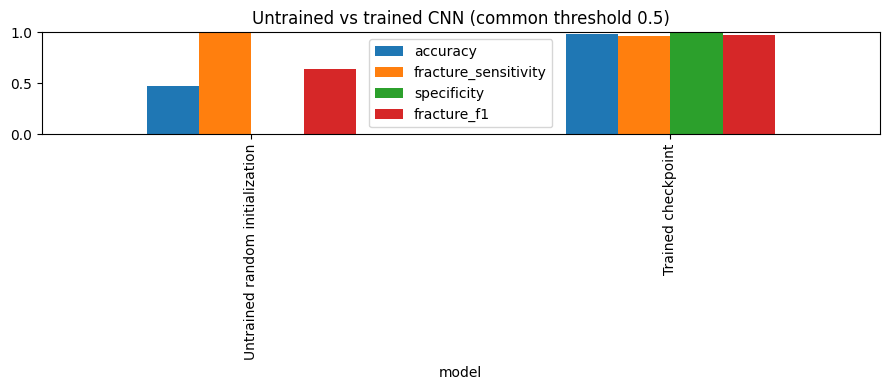

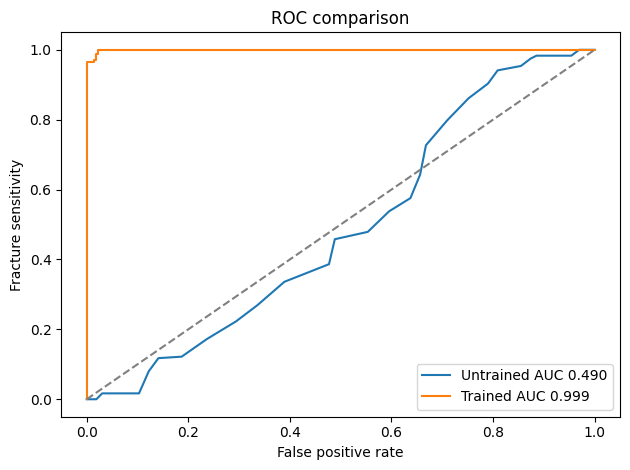

In [3]:
def binary_metrics(y,probs,threshold=.5):
 pred=np.where(probs[:,0]>=threshold,0,1);cm=confusion_matrix(y,pred,labels=[0,1]);tp=cm[0,0];fn=cm[0,1];fp=cm[1,0];tn=cm[1,1]
 return {'accuracy':accuracy_score(y,pred),'fracture_precision':precision_score(y,pred,pos_label=0,zero_division=0),'fracture_sensitivity':tp/(tp+fn) if tp+fn else None,'specificity':tn/(tn+fp) if tn+fp else None,'fracture_f1':f1_score(y,pred,pos_label=0,zero_division=0),'roc_auc':roc_auc_score(y==0,probs[:,0]) if len(np.unique(y))==2 else None,'pr_auc':average_precision_score(y==0,probs[:,0]) if len(np.unique(y))==2 else None,'confusion_matrix':cm.tolist()}
if 'pa' in globals() and len(y):
 mb=binary_metrics(y,pb,.5);ma=binary_metrics(y,pa,.5);app_metrics=binary_metrics(y,pa,app_threshold)
 metrics={'n':len(y),'class_names':list(XRAY_CLASS_NAMES),'positive_class':'fractured','common_threshold':.5,'untrained_random_initialization':mb,'trained_checkpoint':ma,'trained_checkpoint_at_app_threshold':{'threshold':app_threshold,**app_metrics},'device':str(device),'seed':XRAY_SEED,'checkpoint':str(XRAY_MODEL_PATH)}
 summary=pd.DataFrame([{'model':'Untrained random initialization',**{k:v for k,v in mb.items() if not isinstance(v,list)}},{'model':'Trained checkpoint',**{k:v for k,v in ma.items() if not isinstance(v,list)}}]);display(summary)
 summary.set_index('model')[['accuracy','fracture_sensitivity','specificity','fracture_f1']].plot.bar(figsize=(9,4),ylim=(0,1),title='Untrained vs trained CNN (common threshold 0.5)');plt.tight_layout();plt.savefig(OUT/'figures/fracture_cnn_untrained_vs_trained.png',dpi=150);plt.show()
 from sklearn.metrics import roc_curve
 f0,t0,_=roc_curve(y==0,pb[:,0]);f1,t1,_=roc_curve(y==0,pa[:,0]);plt.plot(f0,t0,label=f'Untrained AUC {mb["roc_auc"]:.3f}');plt.plot(f1,t1,label=f'Trained AUC {ma["roc_auc"]:.3f}');plt.plot([0,1],[0,1],'--',color='gray');plt.xlabel('False positive rate');plt.ylabel('Fracture sensitivity');plt.title('ROC comparison');plt.legend();plt.tight_layout();plt.savefig(OUT/'figures/fracture_cnn_untrained_vs_trained_roc.png',dpi=150);plt.show()
 rows=[]
 for i,(path,truth,_) in enumerate(samples):rows.append({'id':path.name,'path':str(path),'true':XRAY_CLASS_NAMES[truth],'untrained_pred':XRAY_CLASS_NAMES[int(pb[i].argmax())],'untrained_fracture_score':float(pb[i,0]),'trained_pred':XRAY_CLASS_NAMES[int(pa[i].argmax())],'trained_fracture_score':float(pa[i,0])})
 pd.DataFrame(rows).to_csv(OUT/'tables/fracture_cnn_untrained_vs_trained.csv',index=False);save(OUT/'metrics/fracture_cnn_untrained_vs_trained.json',meta(ROOT,'fracture_cnn_before_after_training',metrics=metrics))
else: print('Comparison outputs NOT RUN: model or test predictions unavailable.')


## Interpretation and limitations

The random-initialization comparison measures the value of training this architecture on this test folder; it is not a pretrained-vs-fine-tuned comparison. No training curves or pretrained fracture baseline are available. This binary task does not assess fracture location, type, clinical utility, or score calibration. The test set’s independence limitations are documented elsewhere in this project.